# Machine Learning Models: Phishing Email Detection
---
CST-383 Introduction to Data Science<br>
Professor Ergezer<br>
10/24/2025

## Authors:
Alan Becker<br>
Alexander Zambie<br>
Brennan Slate<br>
Lazaro Martinez Jimenez


In [1]:
# required packages
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
import xgboost as xgb

## Read Data

In [2]:
df = pd.read_csv('data/CEAS_08.csv')

## Data Exploration and Cleaning

Looking at the data, there are 2 columns with missing values. 462 instances in the `receiver` column, and 28 in the `subject` column. Majority of the types are objects, with labesl and url's being int64.

In [3]:
na_per_col = df.isna().sum().sort_values(ascending=False)
print(na_per_col)
print(df.info())

receiver    462
subject      28
sender        0
date          0
body          0
label         0
urls          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sender    39154 non-null  object
 1   receiver  38692 non-null  object
 2   date      39154 non-null  object
 3   subject   39126 non-null  object
 4   body      39154 non-null  object
 5   label     39154 non-null  int64 
 6   urls      39154 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 2.1+ MB
None


## Data Preprocessing

Preparing the data for modeling by dropping unnecessary columns and handling missing values. Receiver and date will be dropped, as they do not have much impact on determining if an email is phishing or legitimate. The NA values of subject have been filled with "".

Additionally, the Object types of sender, receiver, subject, and urls were changed to strings for future use.

In [4]:
df = df.drop(["receiver", "date"], axis=1)
df = df.fillna('')
df["urls"] = df["urls"].astype("string").fillna("").str.strip()
df["sender"] = df["sender"].astype("string").fillna("").str.strip()
df["subject"] = df["subject"].astype("string").fillna("").str.strip()


## Data Exploration and Visualization


In [5]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   sender   39154 non-null  string
 1   subject  39154 non-null  string
 2   body     39154 non-null  object
 3   label    39154 non-null  int64 
 4   urls     39154 non-null  string
dtypes: int64(1), object(1), string(3)
memory usage: 1.5+ MB


,sender,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


## Count Plot of Features

Although there are imbalances in the distribution of some of these features, they capture meaningful behavioral differences between legitimate and phishing emails, so these features are kept for modeling.

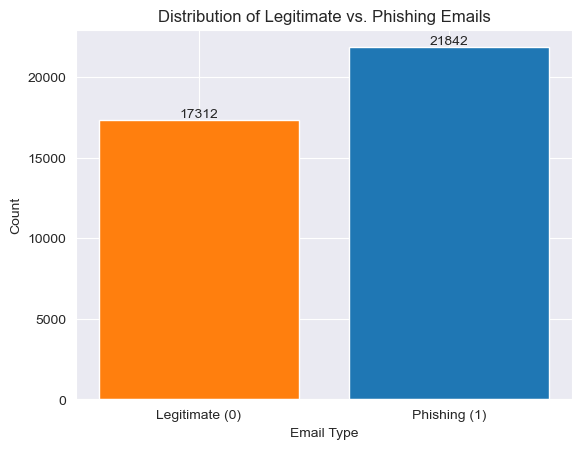

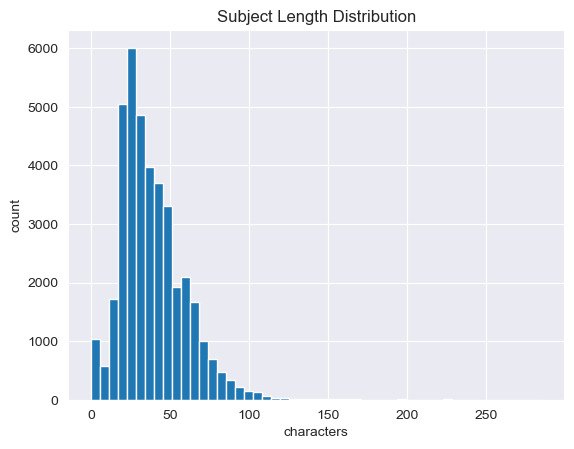

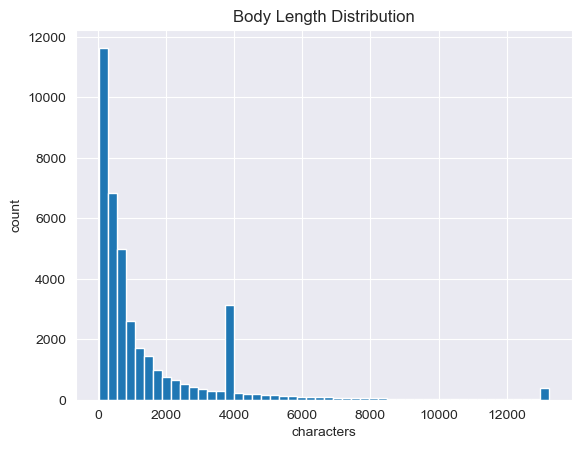

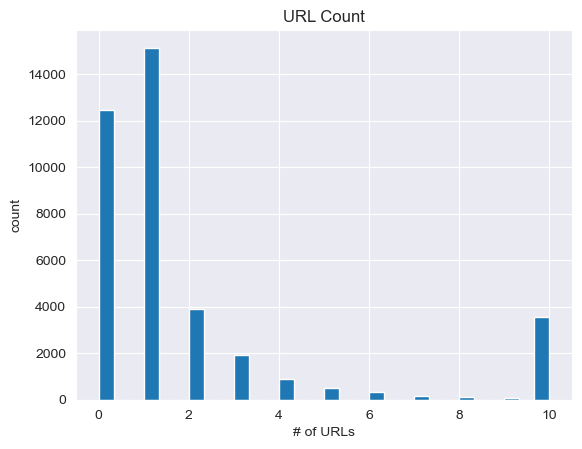

In [6]:
url_pattern = r"(https?://|www\.)\S+" 

df["n_urls"] = (
    df["urls"].str.count(url_pattern) +
    df["subject"].str.count(url_pattern) +
    df["body"].str.count(url_pattern)
)

df["subject_len"] = df["subject"].str.len()
df["body_len"] = df["body"].str.len()

bar_colors = ['#1f77b4', '#ff7f0e']

# Legit vs Phishing Count
count = df['label'].value_counts()
bars = plt.bar(count.index, count.values, color=bar_colors)
plt.title('Distribution of Legitimate vs. Phishing Emails')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.xticks([0, 1], ['Legitimate (0)', 'Phishing (1)'])
plt.bar_label(bars, fmt='%d', fontsize=10)
plt.show()

# Subject length
plt.figure()
df["subject_len"].plot(kind="hist", bins=50)
plt.title("Subject Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()

#Body length
plt.figure()
df["body_len"].clip(upper=df["body_len"].quantile(0.99)).plot(kind="hist", bins=50)
plt.title("Body Length Distribution")
plt.xlabel("characters")
plt.ylabel("count")
plt.show()

# URL's per email count
plt.figure()
df["n_urls"].clip(upper=10).plot(kind="hist", bins=30)
plt.title("URL Count")
plt.xlabel("# of URLs")
plt.ylabel("count")
plt.show()



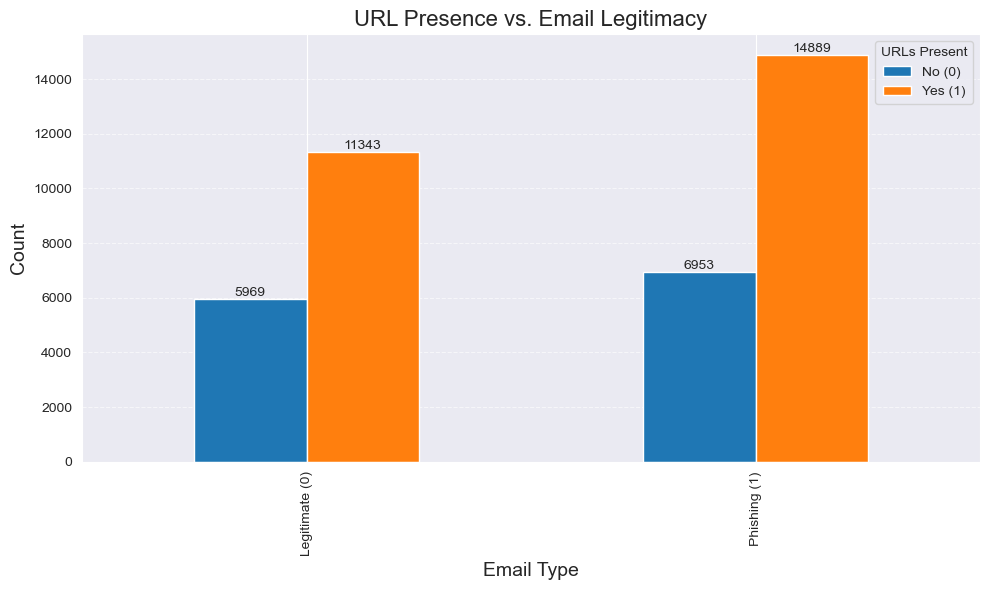

In [7]:
plot_data = pd.crosstab(df['label'], df['urls'])
fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind='bar', ax=ax, color=bar_colors)
ax.set_title('URL Presence vs. Email Legitimacy', fontsize=16)
ax.set_xlabel('Email Type', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
ax.legend(title='URLs Present', labels=['No (0)', 'Yes (1)'], loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Machine Learning Models

In [8]:
df['predictor'] = (df['subject'] + ' ' + df['body'] + ' ' + df['sender']) + ' ' + df['urls'].astype(str)
vectorizer = TfidfVectorizer()
X = df['predictor']
y = df['label'].values
# Splitting the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Applying TFIDF vectorizer after splitting the data
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

In [9]:
model_perf_results = [] # to store model metrics for comparison later

# Function to evaluate models
def eval_model(model, X_train, y_train, X_test, y_test):
    start_time = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_time

    pred_time_start = time.time()
    y_pred = model.predict(X_test)
    pred_time = time.time() - pred_time_start

    # Use predict_proba or decision_function for probabilities depending on the model
    if hasattr(model, "predict_proba"):
      y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
      y_prob = model.decision_function(X_test)
    else:
      raise ValueError("model does not use predict_proba or decision_function method.")

    model_names = {
      "MultinomialNB": "Naive Bayes",
      "LogisticRegression": "Logistic Regression",
      "KNeighborsClassifier": "K-Nearest Neighbors",
      "RandomForestClassifier": "Random Forest",
      "LinearSVC": "Linear SVC",
      "XGBClassifier": "XGBoost",
      "DummyClassifier": "Dummy Classifier"
    }

    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    # Confusion Matrix
    labels = sorted(np.unique(y_test))
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(values_format="d", cmap="Blues")
    plt.title(f"Confusion Matrix for {model_names[model.__class__.__name__]}")
    plt.show()

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_nb = roc_auc_score(y_test, y_prob)

    plt.figure()
    plt.plot(fpr, tpr, label=f"{model_names[model.__class__.__name__]} (AUC = {auc_nb:.2f})")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve for {model_names[model.__class__.__name__]}")
    plt.legend(loc="lower right")
    plt.show()

    # Model performance metrics
    print(f"Model Training Time: {train_time:.4f} seconds")
    print(f"Prediction Time: {pred_time:.4f} seconds")
    print("Train Accuracy: {:.2f}%".format(train_score*100))
    print("Test Accuracy: {:.2f}%".format(test_score*100))
    print("Cohen's Kappa:", round(cohen_kappa_score(y_test, y_pred), 3))
    print(model_names[model.__class__.__name__] + " Classification Report")
    print(classification_report(y_test, y_pred, zero_division=0))


    model_perf_results.append({
        "Model": model_names[model.__class__.__name__],
        "Train Time (s)": train_time,
        "Prediction Time (s)": pred_time,
        "Train Accuracy": train_score,
        "Test Accuracy": test_score
    })

## Dummy Model Approach

The "dummy" model will serve as a baseline for comparison with more sophisticated models.

This model makes predictions by generating random labels based on the distribution of the training data instead of learning from the features.

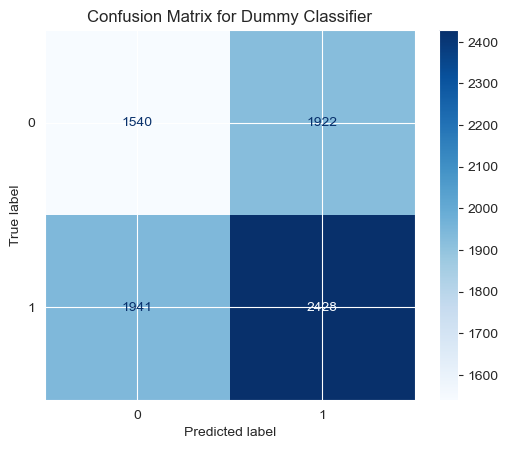

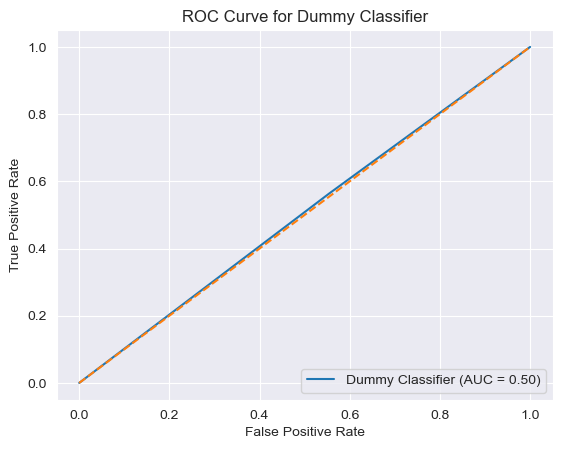

Model Training Time: 0.0011 seconds
Prediction Time: 0.0004 seconds
Train Accuracy: 50.21%
Test Accuracy: 50.76%
Cohen's Kappa: 0.001
Dummy Classifier Classification Report
              precision    recall  f1-score   support

           0       0.44      0.44      0.44      3462
           1       0.56      0.56      0.56      4369

    accuracy                           0.51      7831
   macro avg       0.50      0.50      0.50      7831
weighted avg       0.51      0.51      0.51      7831



In [10]:
dummy_model = DummyClassifier(strategy="stratified")
eval_model(dummy_model, X_train, y_train, X_test, y_test)

## KNN (K-Nearest Neighbors) Approach

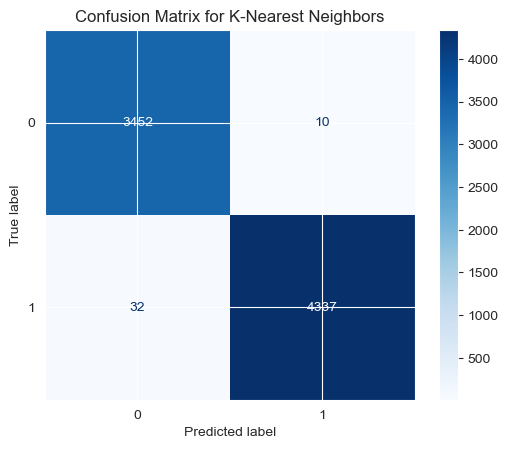

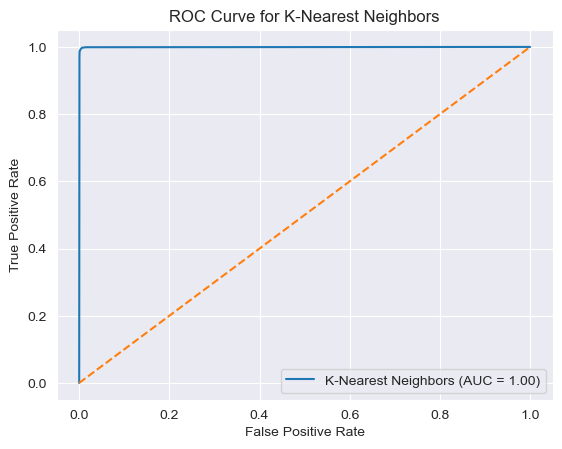

Model Training Time: 0.0109 seconds
Prediction Time: 10.1737 seconds
Train Accuracy: 99.68%
Test Accuracy: 99.46%
Cohen's Kappa: 0.989
K-Nearest Neighbors Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3462
           1       1.00      0.99      1.00      4369

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [11]:
knn_model = KNeighborsClassifier()
eval_model(knn_model, X_train, y_train, X_test, y_test)

## Naives Bayes Approach

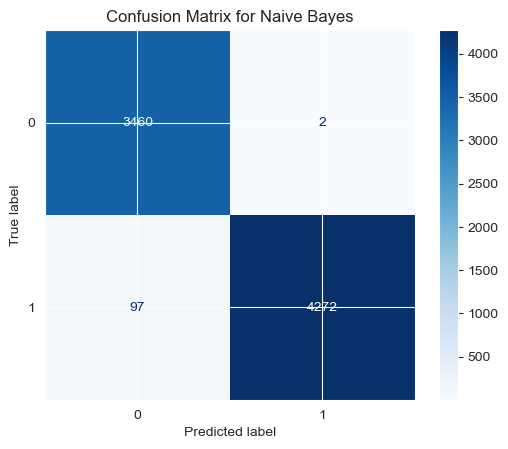

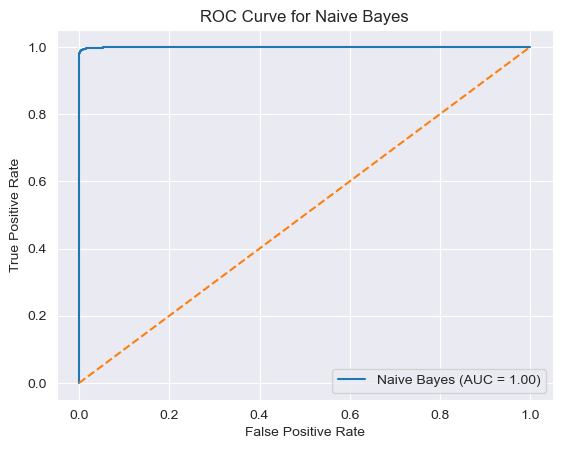

Model Training Time: 0.0249 seconds
Prediction Time: 0.0058 seconds
Train Accuracy: 99.07%
Test Accuracy: 98.74%
Cohen's Kappa: 0.974
Naive Bayes Classification Report
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3462
           1       1.00      0.98      0.99      4369

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [12]:
naivebayes_model = MultinomialNB()
eval_model(naivebayes_model, X_train, y_train, X_test, y_test)

## Logistic Regression Approach

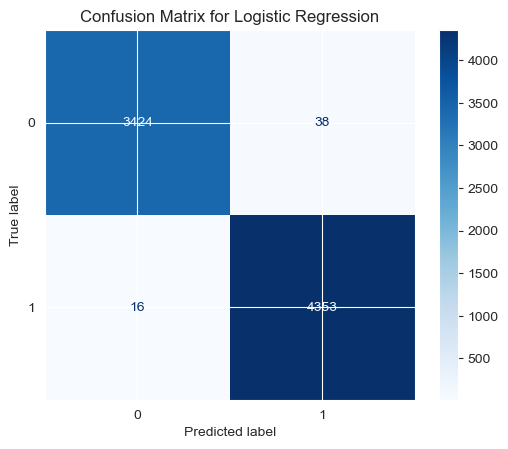

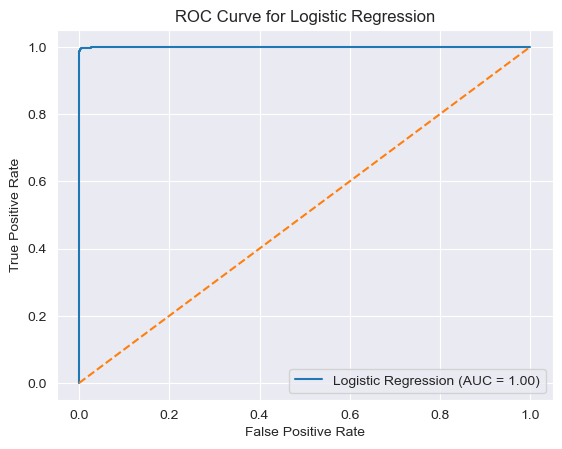

Model Training Time: 0.7287 seconds
Prediction Time: 0.0032 seconds
Train Accuracy: 99.56%
Test Accuracy: 99.31%
Cohen's Kappa: 0.986
Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3462
           1       0.99      1.00      0.99      4369

    accuracy                           0.99      7831
   macro avg       0.99      0.99      0.99      7831
weighted avg       0.99      0.99      0.99      7831



In [13]:
model = LogisticRegression()
eval_model(model, X_train, y_train, X_test, y_test)

## Random Forest Model

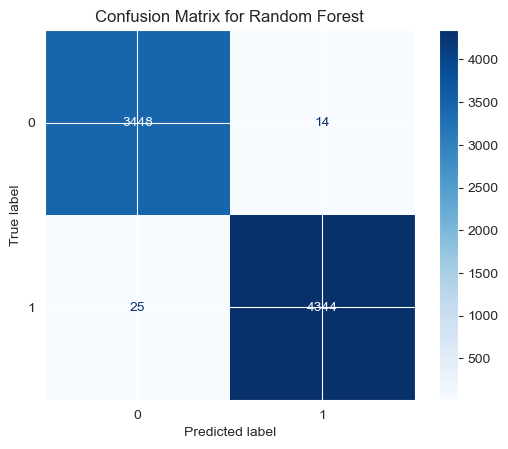

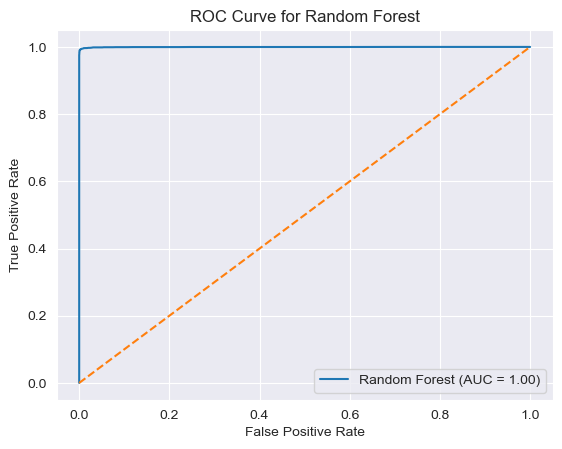

Model Training Time: 5.6439 seconds
Prediction Time: 0.0956 seconds
Train Accuracy: 100.00%
Test Accuracy: 99.50%
Cohen's Kappa: 0.99
Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3462
           1       1.00      0.99      1.00      4369

    accuracy                           1.00      7831
   macro avg       0.99      1.00      0.99      7831
weighted avg       1.00      1.00      1.00      7831



In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None,
    n_jobs=-1
)
eval_model(rf_model, X_train, y_train, X_test, y_test)

## Linear SVC Approach

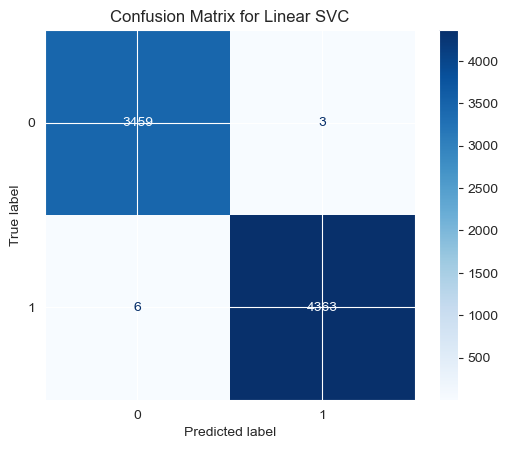

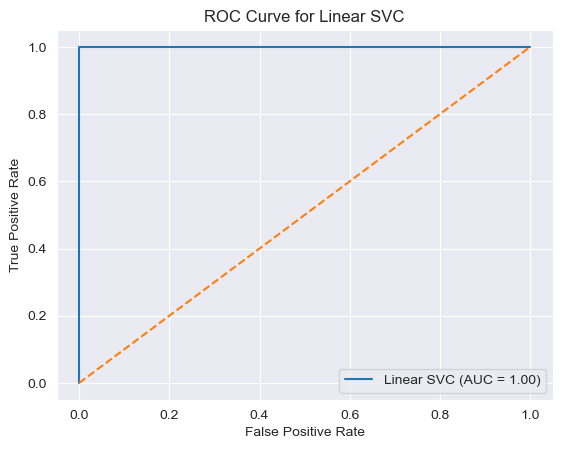

Model Training Time: 0.1788 seconds
Prediction Time: 0.0024 seconds
Train Accuracy: 100.00%
Test Accuracy: 99.89%
Cohen's Kappa: 0.998
Linear SVC Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3462
           1       1.00      1.00      1.00      4369

    accuracy                           1.00      7831
   macro avg       1.00      1.00      1.00      7831
weighted avg       1.00      1.00      1.00      7831



In [15]:
# Initialize, Fit, & Evaluate
svc_model = LinearSVC(random_state=42)
eval_model(svc_model, X_train, y_train, X_test, y_test)

## XGBoost Approach

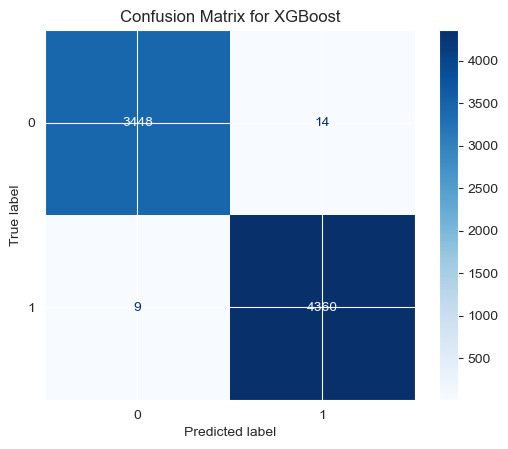

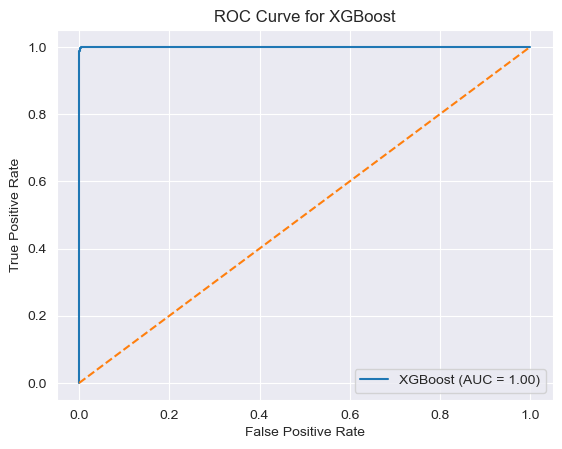

Model Training Time: 26.5996 seconds
Prediction Time: 0.0412 seconds
Train Accuracy: 99.96%
Test Accuracy: 99.71%
Cohen's Kappa: 0.994
XGBoost Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3462
           1       1.00      1.00      1.00      4369

    accuracy                           1.00      7831
   macro avg       1.00      1.00      1.00      7831
weighted avg       1.00      1.00      1.00      7831



In [16]:
# Initialize, Fit & Evaluate
xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
eval_model(xgb_model, X_train, y_train, X_test, y_test)

## Model Performance Results

In [17]:
results_df = pd.DataFrame(model_perf_results)
results_df["Train Accuracy"] = results_df["Train Accuracy"] * 100
results_df["Test Accuracy"] = results_df["Test Accuracy"] * 100
results_df

,Model,Train Time (s),Prediction Time (s),Train Accuracy,Test Accuracy
0,Dummy Classifier,0.001143,0.000386,50.209112,50.759801
1,K-Nearest Neighbors,0.010945,10.173748,99.677553,99.463670
2,Naive Bayes,0.024866,0.005758,99.070970,98.735794
3,Logistic Regression,0.728716,0.003175,99.562622,99.310433
4,Random Forest,5.643948,0.095611,100.000000,99.501979
5,Linear SVC,0.178795,0.002369,99.996807,99.885072
6,XGBoost,26.599630,0.041223,99.961689,99.706295


## Visualizing Model Performance

Visual comparison of train and test accuracies for each model, using a strip plot.

Dummy Classifier accuracy is plotted separately to maintain visibility of the other models' accuracies.

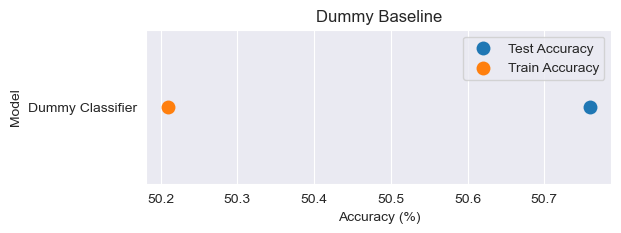

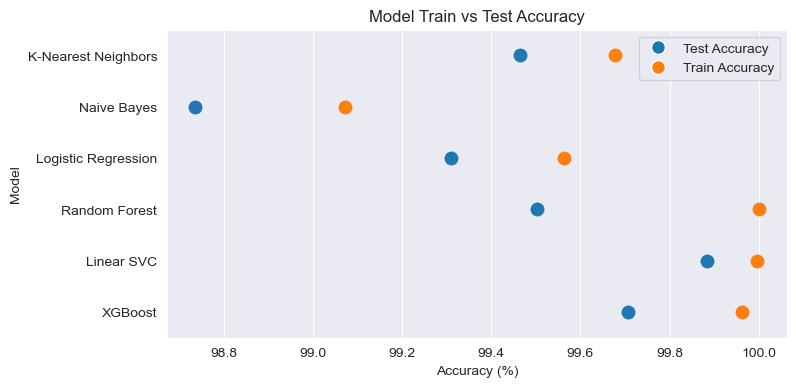

In [18]:
dummy_df = results_df[results_df["Model"] == "Dummy Classifier"]
no_dummy_df = results_df[results_df["Model"] != "Dummy Classifier"]

# Plotting for Dummy baseline for better visibility
plt.figure(figsize=(6, 2))
sns.stripplot(data=dummy_df, x="Test Accuracy", y="Model", size=10, label="Test Accuracy")
sns.stripplot(data=dummy_df, x="Train Accuracy", y="Model", size=10, label="Train Accuracy")
plt.xlabel("Accuracy (%)")
plt.title("Dummy Baseline")

# Plotting Train vs Test Accuracy for other models
plt.figure(figsize=(8, 4))
sns.stripplot(data=no_dummy_df, x="Test Accuracy", y="Model", size=10, label="Test Accuracy")
sns.stripplot(data=no_dummy_df, x="Train Accuracy", y="Model", size=10, label="Train Accuracy")
plt.xlabel("Accuracy (%)")
plt.title("Model Train vs Test Accuracy")

# Fixing legend colors that were not differentiated properly
legend_handles = [
    plt.Line2D([0], [0], marker='o', linestyle='None', color='w',
           markerfacecolor='#1f77b4', markersize=10, label='Test Accuracy'),
    plt.Line2D([0], [0], marker='o', linestyle='None', color='w',
           markerfacecolor='#ff7f0e', markersize=10, label='Train Accuracy')]
plt.legend(handles=legend_handles)
plt.show()

From the results, it is evident that the Random Forest, Linear SVC, and XGBoost models performed the best, achieving extremely high accuracy on both training and test datasets.

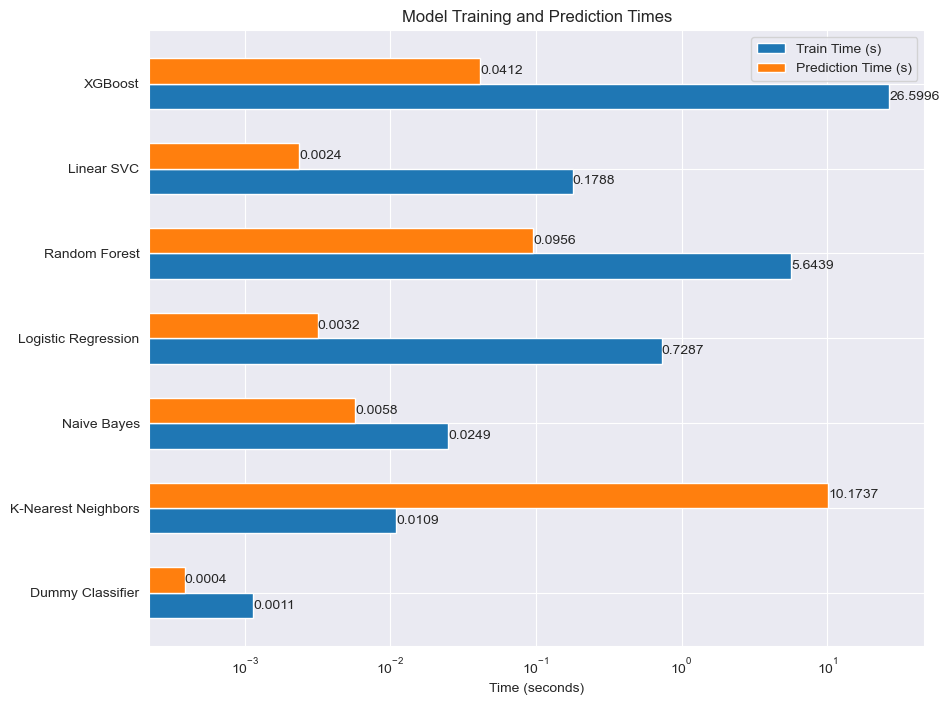

In [19]:
x = np.arange(len(results_df['Model']))  # the label locations
bar_width = 0.3  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 8))
bars1 = ax.barh(x - bar_width/2, results_df['Train Time (s)'], bar_width, label='Train Time (s)')
bars2 = ax.barh(x + bar_width/2, results_df['Prediction Time (s)'], bar_width, label='Prediction Time (s)')
ax.set_xlabel('Time (seconds)')
ax.set_title('Model Training and Prediction Times')
ax.set_yticks(x)
ax.set_yticklabels(results_df['Model'])
ax.set_xscale('log') # using logarithmic scale for better visualization
ax.bar_label(bars1, fmt='%.4f')
ax.bar_label(bars2, fmt='%.4f')
ax.legend()

